# Regresión logística por actividad productiva (municipios rurales) — objetivo: tasa de deforestación > 0, prueba 2025

> **Versión rural.** Mismo modelo y mismo procedimiento que `regresion_logistica_municipios_con_bosque.ipynb`, pero con la **muestra del gradient
> boosting** del equipo (`modelos y clusters/gradient_boosting.ipynb`): solo municipios **rurales y rurales
> dispersos** (clasificación del DNP) con tasa de deforestación calculable. Son 639 municipios por año, 2.556
> filas de entrenamiento (2021–2024) y 639 de prueba (2025), exactamente las mismas filas del gradient boosting.
> No se exige el mínimo de 100 ha de bosque de la versión anterior. En la comparación de modelos se incluye
> también el gradient boosting, porque ahora los tres se evalúan sobre los mismos municipios.


**Pregunta.** ¿El crédito de cada cadena (FINAGRO), el área cosechada de cada cultivo (EVA) y la ganadería (ICA)
de un municipio en un año ayudan a anticipar si **tendrá alguna deforestación** (tasa de deforestación del
IDEAM > 0) el año siguiente? ¿Cuál es la dirección y el tamaño de cada asociación?

**Punto de partida.** Las mismas 15 variables, la misma variable objetivo (tasa > 0) y la misma partición
temporal (entrenamiento 2021–2024, prueba 2025) del Random Forest `random_forest.ipynb`. A diferencia del
bosque, la regresión logística exige revisar la multicolinealidad, y se eliminan las variables que lo requieran.

**Pasos** (se omite el análisis exploratorio):

1. Carga de datos
2. Variable objetivo
3. Variables explicativas por actividad (rezagadas un año)
4. Selección de la muestra
5. Partición temporal: entrenamiento 2021–2024 / prueba 2025
6. Preprocesamiento (imputación, estandarización, codificación)
7. Multicolinealidad: VIF iterativo y eliminación de variables
8. Hiperparámetros con `GridSearchCV` (validación cruzada agrupada por municipio)
9. Modelo final
10. Comparación de modelos en 2025: AUC
11. Comparación de modelos en 2025: matriz de confusión
12. Interpretación: *odds ratios*, errores robustos por municipio, efectos marginales y pruebas por bloque
13. Comparación de especificaciones (estructural, principal, con persistencia)
14. Guardado
15. Conclusiones

## 1. Carga de datos

In [1]:
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.max_columns", 40, "display.width", 200)
SEMILLA = 42

panel = pd.read_parquet("datos/analisis/municipio_anio.parquet")
print(panel.shape)

(6738, 28)


## 2. Variable objetivo

`deforesta` = 1 si la **tasa de deforestación del IDEAM** (`def_ideam_ha / bosque_ideam_ha`) del municipio en el
año *t* es **mayor que 0**; 0 si es cero. Como todos los municipios de la muestra tienen bosque, equivale a
"perdió alguna superficie de bosque, aunque sea una fracción de hectárea". Es la misma regla del Random Forest
correspondiente.

In [2]:
REGLA_OBJETIVO = "tasa_def_ideam > 0"

panel = panel.sort_values(["cod_dane", "anio"]).reset_index(drop=True)
panel["deforesta"] = np.where(panel.tasa_def_ideam.isna(), np.nan, (panel.tasa_def_ideam > 0).astype(float))

## 3. Variables explicativas por actividad productiva

Son las 15 variables iniciales del Random Forest final. Crédito, cultivos y ganado son de *t − 1* y están en
log(1 + x). En la logística **el logaritmo sí importa**: el modelo supone que el logit cambia linealmente con cada
variable, y el log hace que esa linealidad sea razonable para montos y áreas muy asimétricos.

| # | Variable | Definición (en *t − 1*) | Fuente |
|---|---|---|---|
| 1–5 | `log_credito_ganaderia`, `_cafe`, `_arroz`, `_cacao`, `_palma` | Crédito del eslabón de producción de cada cadena (millones de pesos) | FINAGRO |
| 6 | `log_credito_otras_cadenas` | Crédito de producción de las demás cadenas | FINAGRO |
| 7–10 | `log_cosechada_cafe`, `_arroz`, `_palma`, `_cacao` | Hectáreas cosechadas de cada cultivo | EVA |
| 11 | `log_cosechada_otros` | Hectáreas cosechadas de los demás cultivos | EVA |
| 12 | `log_bovinos` | Inventario bovino | ICA |
| 13 | `log_bosque_inicial` | Bosque al inicio del panel (fija) | IDEAM |
| 14–15 | `region`, `ruralidad` | Atributos del municipio (categóricas) | Municipios |

También se construyen las variables del modelo logístico de totales (9 variables), solo para compararlo en el paso 10.

In [3]:
p = panel.copy()
CADENAS = {"ganaderia": "credito_ganaderia_produccion_mm", "cafe": "credito_cafe_produccion_mm",
           "arroz": "credito_arroz_produccion_mm", "cacao": "credito_cacao_produccion_mm",
           "palma": "credito_palma_produccion_mm"}
CULTIVOS = {"cafe": "cosechada_cafe_ha", "arroz": "cosechada_arroz_ha", "palma": "cosechada_palma_ha",
            "cacao": "cosechada_cacao_ha"}
p["credito_otras_cadenas_mm"] = (p.credito_produccion_mm - p[list(CADENAS.values())].sum(axis=1)).clip(lower=0)
p["cosechada_otros_ha"] = (p.area_cosechada_ha - p[list(CULTIVOS.values())].sum(axis=1, min_count=1)).clip(lower=0)

# Variables del modelo anterior de 9 variables (solo para comparar)
p["credito_otro_mm"] = (p.credito_mm - p.credito_produccion_mm).clip(lower=0)
cred_prod = p.credito_produccion_mm.replace(0, np.nan)
p["prop_cred_ganaderia_t"] = (p.credito_ganaderia_produccion_mm / cred_prod).fillna(0)
p["prop_cred_permanentes_t"] = (p[["credito_palma_produccion_mm", "credito_cacao_produccion_mm",
                                   "credito_cafe_produccion_mm"]].sum(axis=1) / cred_prod).fillna(0)

g = p.groupby("cod_dane", observed=True)
assert (g.anio.diff().dropna() == 1).all(), "hay anios faltantes dentro de algun municipio"
a_rezagar = {**{f"log_credito_{k}": v for k, v in CADENAS.items()},
             "log_credito_otras_cadenas": "credito_otras_cadenas_mm",
             **{f"log_cosechada_{k}": v for k, v in CULTIVOS.items()},
             "log_cosechada_otros": "cosechada_otros_ha",
             "log_bovinos": "bovinos", "log_def_l1": "def_ideam_ha",
             "log_credito_prod": "credito_produccion_mm", "log_credito_otro": "credito_otro_mm",
             "log_area_cosechada": "area_cosechada_ha"}
for nuevo, col in a_rezagar.items():
    p[nuevo] = np.log1p(g[col].shift(1))
p["prop_cred_ganaderia"] = g.prop_cred_ganaderia_t.shift(1)
p["prop_cred_permanentes"] = g.prop_cred_permanentes_t.shift(1)
p["log_bosque_inicial"] = np.log1p(p.bosque_ideam_inicial_ha)

CREDITO_INI = [f"log_credito_{k}" for k in CADENAS] + ["log_credito_otras_cadenas"]
COSECHA_INI = [f"log_cosechada_{k}" for k in CULTIVOS] + ["log_cosechada_otros"]
NUMERICAS_INI = CREDITO_INI + COSECHA_INI + ["log_bovinos", "log_bosque_inicial"]
CATEGORICAS = ["region", "ruralidad"]
NUMERICAS_ANT = ["log_credito_prod", "log_credito_otro", "prop_cred_ganaderia", "prop_cred_permanentes",
                 "log_area_cosechada", "log_bovinos", "log_bosque_inicial"]
print(f"Variables iniciales: {len(NUMERICAS_INI)} numericas + {len(CATEGORICAS)} categoricas = {len(NUMERICAS_INI) + len(CATEGORICAS)}")

Variables iniciales: 13 numericas + 2 categoricas = 15


## 4. Selección de la muestra

Misma muestra del gradient boosting: años objetivo 2021–2025, municipios **rurales o rurales dispersos** y con
tasa de deforestación calculable (es decir, con bosque). Se verifica que las filas coincidan exactamente con
las del gradient boosting.

In [4]:
RURALES = ["Rural", "Rural disperso"]
BOSQUE_MIN_HA = 0  # sin minimo de bosque: misma muestra del gradient boosting

muestra = p[p.anio.between(2021, 2025) & p.ruralidad.isin(RURALES) & p.tasa_def_ideam.notna()].copy()
muestra["deforesta"] = muestra.deforesta.astype(int)
print(f"Filas: {len(muestra):,} | municipios: {muestra.cod_dane.nunique():,} | "
      f"0: {(muestra.deforesta == 0).sum():,} | 1: {(muestra.deforesta == 1).sum():,}")

# Verificacion: mismas filas (municipio, anio) que el gradient boosting
import json
celdas_gb = ["".join(c["source"]) for c in json.load(open("modelos y clusters/gradient_boosting.ipynb"))["cells"]]
ns_gb = {"np": np, "pd": pd, "DIR_ANALISIS": Path("datos/analisis")}
exec(celdas_gb[4], ns_gb)  # carga del panel y filtro rural del gradient boosting
exec(celdas_gb[6], ns_gb)  # sus 15 variables y su muestra
filas_gb = set(zip(ns_gb["muestra"].cod_dane.astype(str), ns_gb["muestra"].anio))
filas_propias = set(zip(muestra.cod_dane.astype(str), muestra.anio))
assert filas_gb == filas_propias, "la muestra no coincide con la del gradient boosting"
print("La muestra coincide exactamente con la del gradient boosting.")

Filas: 3,195 | municipios: 639 | 0: 1,176 | 1: 2,019
Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
La muestra coincide exactamente con la del gradient boosting.


## 5. Partición temporal

**Entrenamiento: 2021, 2022, 2023 y 2024. Prueba: 2025.** Es la misma partición del Random Forest
correspondiente, así que los dos modelos se evalúan sobre los mismos 639 municipios de 2025.

In [5]:
ANIOS_TRAIN, ANIOS_TEST = [2021, 2022, 2023, 2024], [2025]
train = muestra[muestra.anio.isin(ANIOS_TRAIN)]
test = muestra[muestra.anio.isin(ANIOS_TEST)]
y_train, y_test = train.deforesta, test.deforesta
grupos_train = train.cod_dane.astype(str)

pd.DataFrame({"filas": [len(train), len(test)], "ceros": [(y_train == 0).sum(), (y_test == 0).sum()],
              "unos": [(y_train == 1).sum(), (y_test == 1).sum()], "tasa_deforesta": [y_train.mean(), y_test.mean()]},
             index=["entrenamiento 2021-2024", "prueba 2025"]).round(3)

,filas,ceros,unos,tasa_deforesta
entrenamiento 2021-2024,2556,947,1609,0.629
prueba 2025,639,229,410,0.642


## 6. Preprocesamiento

A diferencia del Random Forest, la regresión logística **sí necesita estandarizar**:

| Transformación | Por qué |
|---|---|
| **Imputación** (mediana / moda) | `LogisticRegression` no acepta `NaN`. Solo `log_bovinos`, `region` y `ruralidad` tienen 0,1 % de faltantes. |
| **Estandarización** (media 0, desv. 1) | La regularización (L1 o L2) penaliza el tamaño de los coeficientes. Si las variables tienen escalas distintas, unas se penalizan más que otras. Además, así los *odds ratios* se comparan entre variables (efecto de +1 desviación estándar). |
| **One-hot sin la primera categoría** | Con todas las categorías, las dummies suman 1 y son perfectamente colineales con el intercepto. Las bases son región Caribe y ruralidad "Ciudades y aglomeraciones". |

Todo va dentro de un `Pipeline`, así que se aprende solo con el entrenamiento de cada pliegue.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def preprocesador(num):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), CATEGORICAS),
    ], verbose_feature_names_out=False)


def matriz(num, datos, ajustar_en=None):
    """Matriz preprocesada (estandarizada y con dummies) como DataFrame."""
    pre = preprocesador(num).fit((ajustar_en if ajustar_en is not None else datos)[num + CATEGORICAS])
    return pd.DataFrame(pre.transform(datos[num + CATEGORICAS]), columns=pre.get_feature_names_out(), index=datos.index)


X_ini = matriz(NUMERICAS_INI, train)
print(X_ini.shape)
X_ini.describe().T[["mean", "std", "min", "max"]].round(2)

(2556, 19)


,mean,std,min,max
log_credito_ganaderia,-0.00,1.00,-2.83,1.81
log_credito_cafe,-0.00,1.00,-1.18,2.07
log_credito_arroz,0.00,1.00,-0.45,4.13
log_credito_cacao,-0.00,1.00,-0.88,2.90
log_credito_palma,0.00,1.00,-0.33,5.11
log_credito_otras_cadenas,-0.00,1.00,-3.96,2.71
log_cosechada_cafe,0.00,1.00,-1.06,1.97
log_cosechada_arroz,-0.00,1.00,-0.59,3.02
log_cosechada_palma,-0.00,1.00,-0.37,3.76
log_cosechada_cacao,-0.00,1.00,-1.02,2.62


## 7. Multicolinealidad: VIF iterativo

La regresión logística supone que ninguna variable es (casi) una combinación lineal de las demás. Con
colinealidad fuerte, los coeficientes se vuelven inestables, sus errores estándar se inflan y pueden cambiar de
signo. Se usa el **factor de inflación de varianza (VIF)**:

- Se calcula el VIF de todas las columnas sobre el entrenamiento.
- Si la variable numérica con mayor VIF supera **5**, se elimina y se recalcula.
- Se repite hasta que todas queden por debajo de 5.

Las dummies de región y ruralidad no se eliminan, porque son atributos fijos del diseño. Primero se muestran las
correlaciones fuertes, que anticipan qué variables pueden salir.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

corr = train[NUMERICAS_INI].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho_spearman")
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
print("Pares con |correlacion de Spearman| >= 0,6:")
display(pares.round(3).to_frame())


def vif(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns, name="VIF")


UMBRAL_VIF = 5
NUMERICAS = list(NUMERICAS_INI)
historial, eliminadas = [], []
while True:
    v = vif(matriz(NUMERICAS, train))
    historial.append(v.rename(f"ronda {len(historial) + 1}"))
    v_num = v[NUMERICAS]
    if v_num.max() <= UMBRAL_VIF:
        break
    sale = v_num.idxmax()
    print(f"Ronda {len(historial)}: se elimina {sale} (VIF = {v_num.max():.2f})")
    eliminadas.append((sale, round(v_num.max(), 2)))
    NUMERICAS.remove(sale)

print(f"\nVariables eliminadas: {eliminadas if eliminadas else 'ninguna'}")
print(f"VIF maximo final: {historial[-1].max():.2f}")
pd.concat(historial, axis=1).round(2)

Pares con |correlacion de Spearman| >= 0,6:


,,rho_spearman
log_credito_cafe,log_cosechada_cafe,0.924
log_credito_ganaderia,log_bovinos,0.820
log_credito_palma,log_cosechada_palma,0.795
log_credito_cacao,log_cosechada_cacao,0.789
log_credito_arroz,log_cosechada_arroz,0.601


Ronda 1: se elimina log_cosechada_cafe (VIF = 6.76)
Ronda 2: se elimina log_bovinos (VIF = 5.98)

Variables eliminadas: [('log_cosechada_cafe', np.float64(6.76)), ('log_bovinos', np.float64(5.98))]
VIF maximo final: 3.99


,ronda 1,ronda 2,ronda 3
log_credito_ganaderia,4.99,4.98,2.27
log_credito_cafe,6.72,1.56,1.55
log_credito_arroz,2.64,2.64,2.63
log_credito_cacao,3.41,3.41,3.41
log_credito_palma,3.66,3.66,3.65
log_credito_otras_cadenas,2.97,2.96,2.86
log_cosechada_cafe,6.76,NaN,NaN
log_cosechada_arroz,2.93,2.88,2.87
log_cosechada_palma,3.99,3.99,3.99
log_cosechada_cacao,3.86,3.85,3.76


In [8]:
X_COLS = NUMERICAS + CATEGORICAS
X_train, X_test = train[X_COLS], test[X_COLS]
CREDITO = [c for c in CREDITO_INI if c in NUMERICAS]
COSECHA = [c for c in COSECHA_INI if c in NUMERICAS]
print(f"Variables del modelo: {len(NUMERICAS)} numericas + {len(CATEGORICAS)} categoricas = {len(X_COLS)}")
for c in NUMERICAS:
    print("  -", c)

Variables del modelo: 11 numericas + 2 categoricas = 13
  - log_credito_ganaderia
  - log_credito_cafe
  - log_credito_arroz
  - log_credito_cacao
  - log_credito_palma
  - log_credito_otras_cadenas
  - log_cosechada_arroz
  - log_cosechada_palma
  - log_cosechada_cacao
  - log_cosechada_otros
  - log_bosque_inicial


## 8. Hiperparámetros con `GridSearchCV`

- `C`: inverso de la fuerza de regularización (menor = coeficientes más encogidos).
- `penalty`: L2 (ridge) o L1 (lasso, puede llevar coeficientes a cero).
- `class_weight`: sin pesos o `balanced`.

Validación cruzada `GroupKFold` de 5 pliegues **agrupados por municipio**: un municipio nunca está a la vez en
ajuste y validación, porque sus años son muy parecidos y eso inflaría el puntaje.
La métrica es el AUC-ROC.

In [9]:
from sklearn.model_selection import GridSearchCV, GroupKFold

modelo = Pipeline([("pre", preprocesador(NUMERICAS)),
                   ("logit", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEMILLA))])
grilla = {"logit__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100], "logit__penalty": ["l1", "l2"],
          "logit__class_weight": [None, "balanced"]}
cv = GroupKFold(n_splits=5)
busqueda = GridSearchCV(modelo, grilla, cv=cv, scoring=["roc_auc", "average_precision", "neg_log_loss"],
                        refit="roc_auc", n_jobs=-1, return_train_score=True)
inicio = time.time()
busqueda.fit(X_train, y_train, groups=grupos_train)
print(f"{len(busqueda.cv_results_['params'])} combinaciones x 5 pliegues en {time.time() - inicio:.0f} s")
print("Mejor combinacion:", {k.replace('logit__', ''): v for k, v in busqueda.best_params_.items()},
      "| AUC validacion:", round(busqueda.best_score_, 4))

res = pd.DataFrame(busqueda.cv_results_)
cols = {"param_logit__C": "C", "param_logit__penalty": "penalty", "param_logit__class_weight": "class_weight",
        "mean_test_roc_auc": "AUC_val", "std_test_roc_auc": "AUC_val_sd", "mean_train_roc_auc": "AUC_train",
        "mean_test_average_precision": "AP_val", "mean_test_neg_log_loss": "neg_logloss_val"}
tabla_cv = res[list(cols)].rename(columns=cols).sort_values("AUC_val", ascending=False)
tabla_cv.head(10).round(4)

36 combinaciones x 5 pliegues en 3 s
Mejor combinacion: {'C': 3, 'class_weight': 'balanced', 'penalty': 'l2'} | AUC validacion: 0.9134


,C,penalty,class_weight,AUC_val,AUC_val_sd,AUC_train,AP_val,neg_logloss_val
27,3.0,l2,balanced,0.9134,0.0094,0.9181,0.9514,-0.3726
26,3.0,l1,balanced,0.9134,0.0095,0.9182,0.9513,-0.3727
23,1.0,l2,balanced,0.9133,0.0093,0.9178,0.9515,-0.3728
22,1.0,l1,balanced,0.9132,0.0094,0.9178,0.9514,-0.3731
31,10.0,l2,balanced,0.9132,0.0095,0.9182,0.9512,-0.3727
30,10.0,l1,balanced,0.9132,0.0096,0.9183,0.9512,-0.3728
35,100.0,l2,balanced,0.9131,0.0097,0.9183,0.9511,-0.3728
34,100.0,l1,balanced,0.9131,0.0097,0.9183,0.9511,-0.3728
25,3.0,l2,None,0.9131,0.0091,0.9183,0.9510,-0.3558
21,1.0,l2,None,0.9131,0.0090,0.9180,0.9512,-0.3558


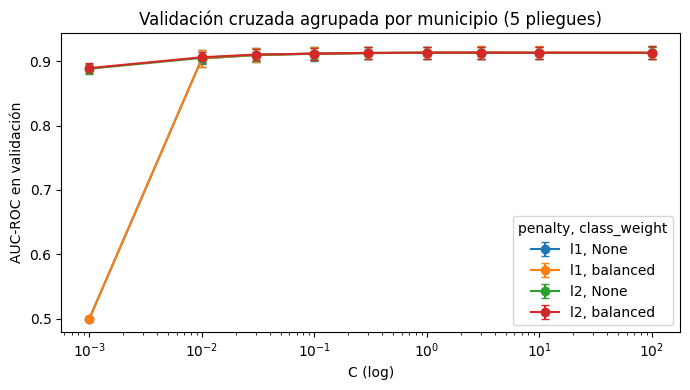

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for (pen, cw), d in tabla_cv.assign(class_weight=tabla_cv.class_weight.astype(str)).groupby(["penalty", "class_weight"]):
    d = d.sort_values("C")
    ax.errorbar(d.C.astype(float), d.AUC_val, yerr=d.AUC_val_sd, marker="o", capsize=3, label=f"{pen}, {cw}")
ax.set_xscale("log"); ax.set_xlabel("C (log)"); ax.set_ylabel("AUC-ROC en validación")
ax.set_title("Validación cruzada agrupada por municipio (5 pliegues)"); ax.legend(title="penalty, class_weight")
plt.tight_layout(); plt.show()

## 9. Modelo final

`GridSearchCV` re-entrena la mejor combinación con todo el entrenamiento (2021–2024).

In [11]:
final = busqueda.best_estimator_
mejores = {k.replace("logit__", ""): v for k, v in busqueda.best_params_.items()}
coef_sk = pd.Series(final.named_steps["logit"].coef_.ravel(), index=final.named_steps["pre"].get_feature_names_out())
print("Coeficientes llevados a cero por la penalizacion:", list(coef_sk[coef_sk == 0].index) or "ninguno")
final

Coeficientes llevados a cero por la penalizacion: ninguno


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('esc',
                                                                   StandardScaler())]),
                                                  ['log_credito_ganaderia',
                                                   'log_credito_cafe',
                                                   'log_credito_arroz',
                                                   'log_credito_cacao',
                                                   'log_credito_palma',
                                                   'log_credito_otras_cadenas',
                                                   'log_cosechada_arroz',
                                                   'log_cosechada_palma',
                                                   'log_cosechada_cacao',
                                                   'log_c...otros',
                                                   'log_bosque_inicial']),
                                                 ('cat',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['region', 'ruralidad'])],
                                   verbose_feature_names_out=False)),
                ('logit',
                 LogisticRegression(C=3, class_weight='balanced', max_iter=5000,
                                    random_state=42, solver='liblinear'))])

## 10. Comparación de modelos: AUC

Los modelos se comparan sobre los mismos 639 municipios de 2025 con el **AUC-ROC**: la probabilidad de que un
municipio que deforestó reciba una probabilidad mayor que uno que no deforestó (0,5 = azar, 1 = perfecto).

- **Logística por actividad:** el modelo de este notebook.
- **Logística de totales (9 variables):** re-entrenada con la misma variable objetivo y el mismo entrenamiento
  (L2, C = 1, sin pesos).
- **Random Forest por actividad:** el modelo guardado de `random_forest.ipynb`.
- **Gradient boosting (equipo):** el modelo guardado de `modelos y clusters/gradient_boosting.ipynb`, con sus
  propias 15 variables (del mismo año que predice). Se evalúa sobre los mismos 639 municipios.
- **Persistencia:** asigna la probabilidad observada en el entrenamiento según si el municipio deforestó o no el
  año anterior.

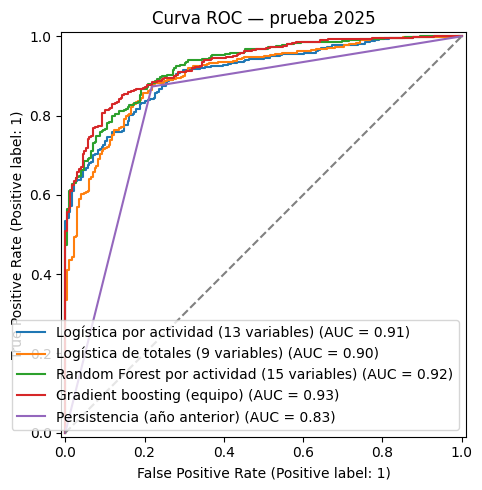

,AUC-ROC
Logística por actividad (13 variables),0.9062
Logística de totales (9 variables),0.9026
Random Forest por actividad (15 variables),0.9246
Gradient boosting (equipo),0.9278
Persistencia (año anterior),0.8274


In [12]:
import joblib
from sklearn.metrics import RocCurveDisplay, roc_auc_score


def metricas(y, prob):
    return {"AUC-ROC": roc_auc_score(y, prob)}


prob_test = final.predict_proba(X_test)[:, 1]
logit_ant = Pipeline([("pre", preprocesador(NUMERICAS_ANT)),
                      ("logit", LogisticRegression(C=1, penalty="l2", solver="liblinear", max_iter=5000))])
logit_ant.fit(train[NUMERICAS_ANT + CATEGORICAS], y_train)

modelos = {f"Logística por actividad ({len(X_COLS)} variables)": prob_test,
           "Logística de totales (9 variables)": logit_ant.predict_proba(test[NUMERICAS_ANT + CATEGORICAS])[:, 1]}
ruta_rf = Path("datos/analisis/modelo_random_forest_rural/modelo_random_forest.joblib")
if ruta_rf.exists():
    rf_guardado = joblib.load(ruta_rf)
    modelos["Random Forest por actividad (15 variables)"] = rf_guardado["modelo"].predict_proba(test[rf_guardado["variables"]])[:, 1]
# --- Gradient boosting del equipo, sobre los mismos municipios de 2025
import lightgbm  # noqa: F401  (necesario para cargar el modelo)
test_gb = ns_gb["muestra"].query("anio == 2025").assign(cod_dane=lambda d: d.cod_dane.astype(str)).set_index("cod_dane")
gb = joblib.load("modelos y clusters/resultados/gradient_boosting_clasificador.joblib")
prob_gb = gb.predict_proba(test_gb.loc[test.cod_dane.astype(str), ns_gb["EXPLICATIVAS"]])[:, 1]
modelos["Gradient boosting (equipo)"] = prob_gb
p["deforesta_l1"] = p.groupby("cod_dane", observed=True).deforesta.shift(1)
tasa_cond = train.assign(l1=p.loc[train.index, "deforesta_l1"]).groupby("l1").deforesta.mean()
modelos["Persistencia (año anterior)"] = p.loc[test.index, "deforesta_l1"].map(tasa_cond).fillna(y_train.mean()).values
tabla_eval = pd.DataFrame({k: metricas(y_test, v) for k, v in modelos.items()}).T

fig, ax = plt.subplots(figsize=(6, 5))
for nombre, prob in modelos.items():
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax, name=nombre)
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_title("Curva ROC — prueba 2025")
plt.tight_layout(); plt.show()
tabla_eval.round(4)

## 11. Comparación de modelos: matriz de confusión

Cada modelo clasifica los municipios de 2025 con el **mismo umbral de 0,5**: si la probabilidad predicha es
0,5 o más, se clasifica como "deforesta". Usar el mismo umbral permite comparar los modelos directamente, y
0,5 es también el umbral que usa el gradient boosting (`predict`).

- **Verdaderos positivos:** municipios que deforestaron y el modelo los detectó.
- **Falsos negativos:** municipios que deforestaron y el modelo no los detectó.
- **Falsos positivos:** municipios que no deforestaron pero el modelo los marcó.
- **Verdaderos negativos:** municipios que no deforestaron y el modelo acertó.

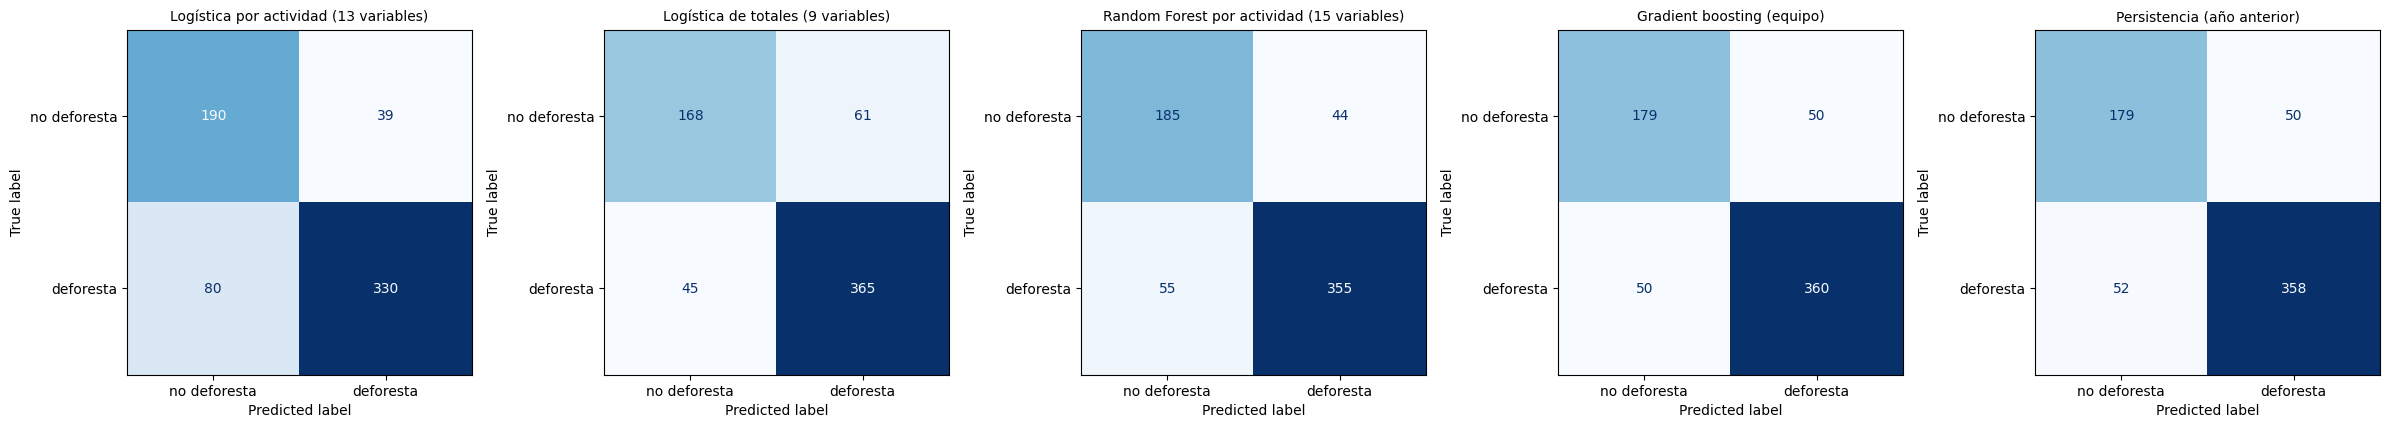

,verdaderos negativos,falsos positivos,falsos negativos,verdaderos positivos,aciertos
modelo,,,,,
Logística por actividad (13 variables),190,39,80,330,520
Logística de totales (9 variables),168,61,45,365,533
Random Forest por actividad (15 variables),185,44,55,355,540
Gradient boosting (equipo),179,50,50,360,539
Persistencia (año anterior),179,50,52,358,537


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

UMBRAL = 0.5
fig, ax = plt.subplots(1, len(modelos), figsize=(4.8 * len(modelos), 4.3))
filas = []
for eje, (nombre, prob) in zip(np.atleast_1d(ax), modelos.items()):
    pred = (prob >= UMBRAL).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["no deforesta", "deforesta"]).plot(ax=eje, cmap="Blues", colorbar=False)
    eje.set_title(nombre, fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    filas.append({"modelo": nombre, "verdaderos negativos": tn, "falsos positivos": fp,
                  "falsos negativos": fn, "verdaderos positivos": tp, "aciertos": tn + tp})
plt.tight_layout(); plt.show()
pred_test = (prob_test >= UMBRAL).astype(int)
matrices = pd.DataFrame(filas).set_index("modelo")
matrices

## 12. Interpretación

Para la inferencia, el modelo se re-estima con `statsmodels` sin regularización ni pesos, para obtener errores
estándar, intervalos y p-valores. Como un mismo municipio aparece en varios años del entrenamiento, sus
observaciones no son independientes, y se usan **errores estándar agrupados por municipio** (*cluster-robust*).
La columna `coef_sklearn` muestra los coeficientes del modelo penalizado, para verificar que coinciden en signo
y magnitud.

Las numéricas están estandarizadas. Así, el **odds ratio (OR)** se lee como: "un aumento de una desviación
estándar en la variable multiplica las odds de deforestar por OR", manteniendo lo demás constante. Las
categóricas se comparan contra la categoría base (región Caribe, ruralidad "Ciudades y aglomeraciones").

In [14]:
X_sm = sm.add_constant(pd.DataFrame(final.named_steps["pre"].transform(X_train),
                                    columns=final.named_steps["pre"].get_feature_names_out(), index=X_train.index))
cluster = pd.factorize(grupos_train)[0]
logit_sm = sm.Logit(y_train, X_sm).fit(disp=0, cov_type="cluster", cov_kwds={"groups": cluster})
print(logit_sm.summary2().tables[0].to_string(header=False, index=False))

ic = logit_sm.conf_int()
coefs = pd.DataFrame({"coef": logit_sm.params, "OR": np.exp(logit_sm.params),
                      "OR_IC95_inf": np.exp(ic[0]), "OR_IC95_sup": np.exp(ic[1]), "p_valor": logit_sm.pvalues,
                      "coef_sklearn": np.r_[final.named_steps["logit"].intercept_, final.named_steps["logit"].coef_.ravel()]})
coefs["signif"] = pd.cut(coefs.p_valor, [0, 0.01, 0.05, 0.1, 1], labels=["***", "**", "*", ""])
coefs.drop("const").sort_values("OR", ascending=False).round(3)

             Model:            Logit           Method:       MLE
Dependent Variable:        deforesta Pseudo R-squared:     0.474
              Date: 2026-11-09 14:56              AIC: 1809.6089
  No. Observations:             2556              BIC: 1914.8405
          Df Model:               17   Log-Likelihood:   -886.80
      Df Residuals:             2538          LL-Null:   -1685.0
         Converged:           1.0000      LLR p-value:    0.0000
    No. Iterations:           8.0000            Scale:    1.0000


,coef,OR,OR_IC95_inf,OR_IC95_sup,p_valor,coef_sklearn,signif
log_bosque_inicial,2.684,14.643,10.778,19.893,0.000,2.707,***
log_cosechada_cacao,0.375,1.455,1.105,1.915,0.008,0.392,***
log_credito_cacao,0.323,1.381,1.088,1.753,0.008,0.321,***
log_cosechada_otros,0.316,1.372,1.060,1.775,0.016,0.316,**
log_credito_arroz,0.148,1.160,0.929,1.448,0.190,0.146,
log_cosechada_arroz,0.096,1.101,0.861,1.408,0.443,0.133,
log_credito_palma,0.010,1.010,0.764,1.335,0.946,-0.019,
ruralidad_Rural disperso,-0.009,0.992,0.719,1.367,0.959,-0.016,
log_cosechada_palma,-0.036,0.964,0.721,1.290,0.807,-0.011,
log_credito_ganaderia,-0.098,0.907,0.667,1.234,0.534,-0.074,


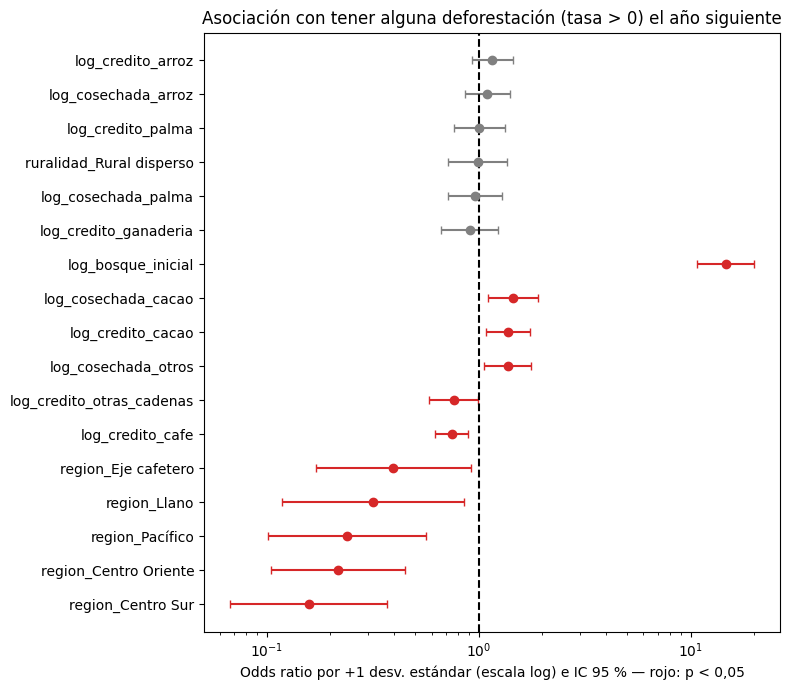

In [15]:
d = coefs.drop("const").sort_values("OR")
fig, ax = plt.subplots(figsize=(8, 7))
for signif, color in [(True, "C3"), (False, "grey")]:
    s = d[(d.p_valor < 0.05) == signif]
    ax.errorbar(s.OR, s.index, xerr=[s.OR - s.OR_IC95_inf, s.OR_IC95_sup - s.OR], fmt="o", capsize=3, color=color)
ax.axvline(1, ls="--", color="black"); ax.set_xscale("log")
ax.set_xlabel("Odds ratio por +1 desv. estándar (escala log) e IC 95 % — rojo: p < 0,05")
ax.set_title("Asociación con tener alguna deforestación (tasa > 0) el año siguiente")
plt.tight_layout(); plt.show()

In [16]:
# Efectos marginales promedio: cambio en la probabilidad (en puntos) por +1 desviacion estandar
print(f"Pseudo-R2 de McFadden: {logit_sm.prsquared:.3f}")
efm = logit_sm.get_margeff(at="overall").summary_frame()
efm = efm.loc[NUMERICAS, ["dy/dx", "Pr(>|z|)", "Conf. Int. Low", "Cont. Int. Hi."]]
efm.insert(1, "puntos_porcentuales", efm["dy/dx"] * 100)
efm.sort_values("dy/dx").round(4)

Pseudo-R2 de McFadden: 0.474


,dy/dx,puntos_porcentuales,Pr(>|z|),Conf. Int. Low,Cont. Int. Hi.
log_credito_cafe,-0.0322,-3.2153,0.0016,-0.0521,-0.0122
log_credito_otras_cadenas,-0.0298,-2.9800,0.0496,-0.0596,-0.0000
log_credito_ganaderia,-0.0108,-1.0842,0.5337,-0.0450,0.0233
log_cosechada_palma,-0.0040,-0.4021,0.8071,-0.0363,0.0283
log_credito_palma,0.0011,0.1066,0.9462,-0.0299,0.0320
log_cosechada_arroz,0.0107,1.0677,0.4430,-0.0166,0.0380
log_credito_arroz,0.0165,1.6454,0.1881,-0.0080,0.0410
log_cosechada_otros,0.0351,3.5058,0.0162,0.0065,0.0636
log_credito_cacao,0.0358,3.5818,0.0081,0.0093,0.0623
log_cosechada_cacao,0.0416,4.1585,0.0067,0.0115,0.0717


### Pesos del modelo final

Los **pesos** son los coeficientes β del modelo final de scikit-learn, con los hiperparámetros elegidos en el paso 8. El modelo calcula
la probabilidad de deforestar como:

$$\text{logit}(p) = \beta_0 + \sum_j \beta_j \, x_j \qquad\Rightarrow\qquad p = \frac{1}{1 + e^{-\text{logit}(p)}}$$

- **Signo del peso:** positivo, la variable sube la probabilidad. Negativo, la baja.
- **`peso` en las numéricas:** cambio del logit por **+1 desviación estándar** de la variable (están
  estandarizadas). `OR_por_sd = e^β` es el factor que multiplica las odds.
- **`OR_duplicar`:** como las numéricas están en log(1 + x), un peso por desviación estándar se traduce en el
  efecto de **duplicar** el crédito, el área o el ganado: `OR_duplicar = e^(β · ln 2 / sd_log)`.
- **`peso` en las dummies:** efecto de pertenecer a esa categoría frente a la base (región Caribe, ruralidad
  "Ciudades y aglomeraciones").
- **`peso_estandarizado` = |β| × desviación estándar de la columna:** pone numéricas y dummies en la misma
  escala (cuánto mueve el logit una variación típica de la columna). De ahí sale la **participación (%)** de cada
  variable y de cada bloque en la influencia total del modelo.

In [17]:
pre_f, logit_f = final.named_steps["pre"], final.named_steps["logit"]
cols_f = pre_f.get_feature_names_out()
Xf_train = pd.DataFrame(pre_f.transform(X_train), columns=cols_f, index=X_train.index)
sd_log = pd.Series(pre_f.named_transformers_["num"].named_steps["esc"].scale_, index=NUMERICAS)

pesos = pd.DataFrame({"peso": logit_f.coef_.ravel()}, index=cols_f)
pesos["OR_por_sd"] = np.exp(pesos.peso)
pesos["OR_duplicar"] = np.exp(pesos.peso.reindex(NUMERICAS) / sd_log * np.log(2))
pesos["peso_estandarizado"] = pesos.peso.abs() * Xf_train.std()
pesos["participacion_%"] = 100 * pesos.peso_estandarizado / pesos.peso_estandarizado.sum()
pesos["p_valor_cluster"] = logit_sm.pvalues.reindex(cols_f)
pesos["direccion"] = np.where(pesos.peso > 0, "sube", "baja")
pesos = pesos.sort_values("peso_estandarizado", ascending=False)
pesos.insert(0, "rango", range(1, len(pesos) + 1))
print(f"Intercepto (beta_0): {logit_f.intercept_[0]:.3f}")
pesos.round(3)

Intercepto (beta_0): 1.753


,rango,peso,OR_por_sd,OR_duplicar,peso_estandarizado,participacion_%,p_valor_cluster,direccion
log_bosque_inicial,1,2.707,14.980,2.231,2.707,39.731,0.000,sube
region_Centro Oriente,2,-1.255,0.285,NaN,0.601,8.822,0.000,baja
region_Centro Sur,3,-1.628,0.196,NaN,0.569,8.349,0.000,baja
region_Pacífico,4,-1.112,0.329,NaN,0.407,5.977,0.001,baja
log_cosechada_cacao,5,0.392,1.481,1.107,0.392,5.760,0.008,sube
log_credito_cafe,6,-0.350,0.704,0.924,0.350,5.143,0.001,baja
log_credito_cacao,7,0.321,1.379,1.094,0.321,4.718,0.008,sube
log_cosechada_otros,8,0.316,1.371,1.140,0.316,4.634,0.016,sube
region_Llano,9,-0.898,0.408,NaN,0.277,4.063,0.024,baja
log_credito_otras_cadenas,10,-0.276,0.758,0.897,0.276,4.058,0.049,baja


In [18]:
def bloque(c):
    if c.startswith("log_credito"):
        return "Crédito por cadena"
    if c.startswith("log_cosechada"):
        return "Cosecha por cultivo"
    if c.startswith("region_"):
        return "Región"
    if c.startswith("ruralidad_"):
        return "Ruralidad"
    return {"log_bovinos": "Bovinos", "log_bosque_inicial": "Bosque inicial"}[c]


def actividad(c):
    for act, nombre in {"ganaderia": "Ganadería", "cafe": "Café", "arroz": "Arroz", "cacao": "Cacao", "palma": "Palma"}.items():
        if c.endswith("_" + act):
            return nombre
    if c == "log_bovinos":
        return "Ganadería"
    if c in ("log_credito_otras_cadenas", "log_cosechada_otros"):
        return "Otras actividades"
    return None


part_bloque = pesos.groupby(pesos.index.map(bloque))["participacion_%"].sum().sort_values(ascending=False)
pesos_act = pesos[pesos.index.map(actividad).notna()]
part_act = pd.DataFrame({
    "participacion_%": pesos_act.groupby(pesos_act.index.map(actividad))["participacion_%"].sum(),
    "suma_pesos": pesos_act.groupby(pesos_act.index.map(actividad))["peso"].sum(),
}).sort_values("participacion_%", ascending=False)
part_act["direccion_neta"] = np.where(part_act.suma_pesos > 0, "sube", "baja")
display(part_bloque.round(1).to_frame())
part_act.round(3)

,participacion_%
Bosque inicial,39.7
Región,30.2
Crédito por cadena,17.4
Cosecha por cultivo,12.5
Ruralidad,0.1


,participacion_%,suma_pesos,direccion_neta
Cacao,10.478,0.714,sube
Otras actividades,8.692,0.039,sube
Café,5.143,-0.350,baja
Arroz,4.090,0.279,sube
Ganadería,1.086,-0.074,baja
Palma,0.428,-0.029,baja


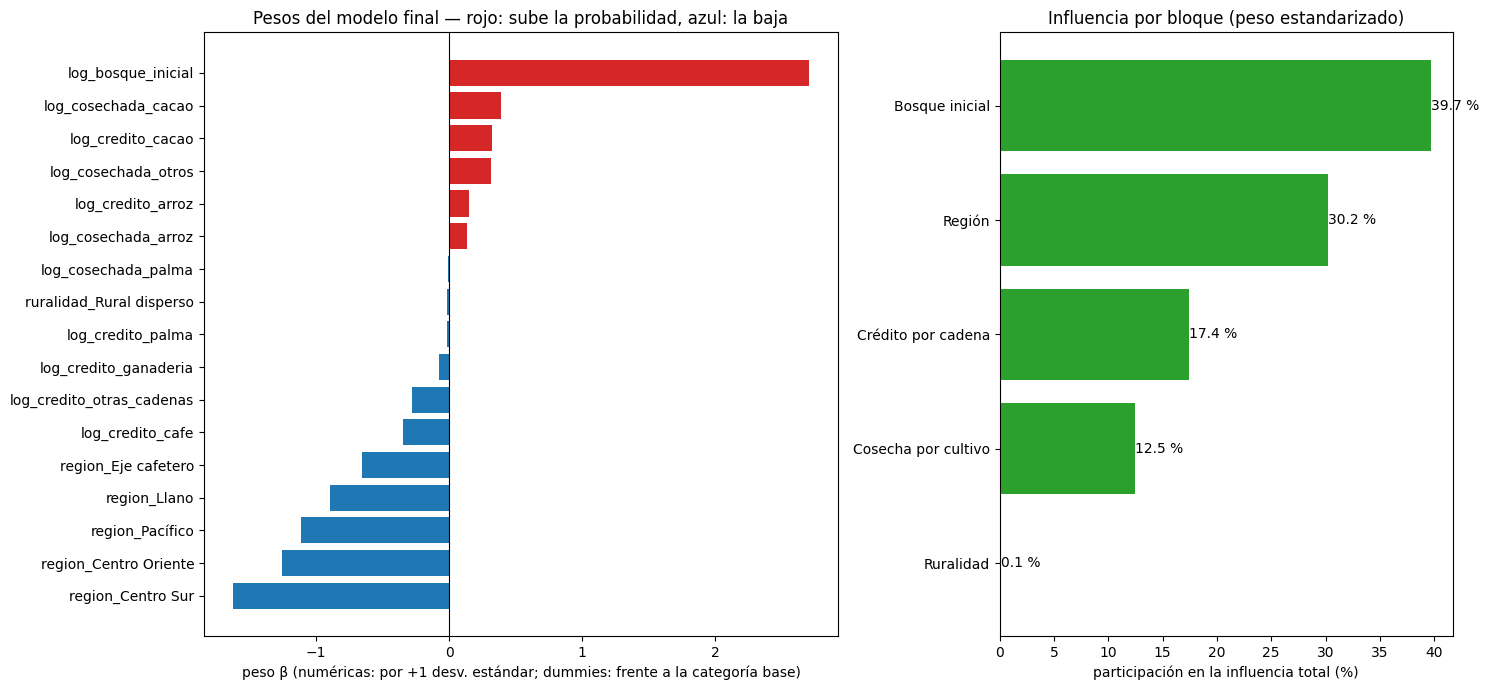

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.4, 1]})
d = pesos.sort_values("peso")
ax[0].barh(d.index, d.peso, color=np.where(d.peso > 0, "C3", "C0"))
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set_xlabel("peso β (numéricas: por +1 desv. estándar; dummies: frente a la categoría base)")
ax[0].set_title("Pesos del modelo final — rojo: sube la probabilidad, azul: la baja")
b = part_bloque.sort_values()
ax[1].barh(b.index, b.values, color="C2")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f %%")
ax[1].set_xlabel("participación en la influencia total (%)")
ax[1].set_title("Influencia por bloque (peso estandarizado)")
plt.tight_layout(); plt.show()

### Pruebas conjuntas por bloque y por actividad

Una prueba de Wald conjunta (con la covarianza agrupada por municipio) responde si **todas** las variables de un
bloque son a la vez cero. Es la versión inferencial de la permutación por bloques del Random Forest, y evita
concluir que una actividad "no importa" solo porque sus variables, correlacionadas entre sí, salen
individualmente no significativas.

In [20]:
def wald(cols):
    cols = [c for c in cols if c in X_sm.columns]
    if not cols:
        return {"n_variables": 0, "chi2": np.nan, "p_valor": np.nan}
    R = np.zeros((len(cols), len(X_sm.columns)))
    for i, c in enumerate(cols):
        R[i, X_sm.columns.get_loc(c)] = 1
    t = logit_sm.wald_test(R, scalar=True)
    return {"n_variables": len(cols), "chi2": float(t.statistic), "p_valor": float(t.pvalue)}


dummies = lambda var: [c for c in X_sm.columns if c.startswith(var + "_")]
bloques = {"Crédito (cadenas)": CREDITO, "Cosecha (cultivos)": COSECHA, "Bovinos": ["log_bovinos"],
           "Bosque inicial": ["log_bosque_inicial"], "Región": dummies("region"), "Ruralidad": dummies("ruralidad")}
actividades = {"Ganadería (crédito + bovinos)": ["log_credito_ganaderia", "log_bovinos"],
               "Café (crédito + área)": ["log_credito_cafe", "log_cosechada_cafe"],
               "Arroz (crédito + área)": ["log_credito_arroz", "log_cosechada_arroz"],
               "Cacao (crédito + área)": ["log_credito_cacao", "log_cosechada_cacao"],
               "Palma (crédito + área)": ["log_credito_palma", "log_cosechada_palma"],
               "Otras actividades (crédito + área)": ["log_credito_otras_cadenas", "log_cosechada_otros"]}
pruebas = pd.concat({"bloque": pd.DataFrame({k: wald(v) for k, v in bloques.items()}).T,
                     "actividad": pd.DataFrame({k: wald(v) for k, v in actividades.items()}).T})
pruebas["signif"] = pd.cut(pruebas.p_valor.astype(float), [-1, 0.01, 0.05, 0.1, 1], labels=["***", "**", "*", ""])
pruebas.round(4)

n_variables      chi2  p_valor signif
bloque    Crédito (cadenas)                           6.0   24.3724   0.0004    ***
          Cosecha (cultivos)                          4.0   16.7015   0.0022    ***
          Bovinos                                     0.0       NaN      NaN    NaN
          Bosque inicial                              1.0  294.7161   0.0000    ***
          Región                                      5.0   27.2810   0.0001    ***
          Ruralidad                                   1.0    0.0027   0.9586       
actividad Ganadería (crédito + bovinos)               1.0    0.3871   0.5338       
          Café (crédito + área)                       1.0   10.1045   0.0015    ***
          Arroz (crédito + área)                      2.0    5.0180   0.0814      *
          Cacao (crédito + área)                      2.0   53.2461   0.0000    ***
          Palma (crédito + área)                      2.0    0.0688   0.9662       
          Otras actividades (crédito + área)          2.0    6.5375   0.0381     **

## 13. Comparación de especificaciones

Con los hiperparámetros elegidos. Como el modelo C necesita la deforestación del año anterior, que no existe
para 2021, los tres se entrenan con 2022–2024 y se evalúan en 2025. Se comparan con el AUC-ROC.

| Modelo | Variables |
|---|---|
| A. Estructural | `log_bosque_inicial`, región, ruralidad |
| B. Principal | A + crédito por cadena, cosecha por cultivo y bovinos (después del VIF) |
| C. Con persistencia | B + deforestación del año anterior (`log_def_l1`) |

In [21]:
especificaciones = {"A. Estructural": ["log_bosque_inicial"], "B. Principal": NUMERICAS,
                    "C. Con persistencia": NUMERICAS + ["log_def_l1"]}
train_c, test_c = train[train.anio >= 2022], test[test.anio >= 2022]
filas = []
for nombre, num in especificaciones.items():
    m = Pipeline([("pre", preprocesador(num)),
                  ("logit", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEMILLA, **mejores))])
    m.fit(train_c[num + CATEGORICAS], train_c.deforesta)
    filas.append({"modelo": nombre, "n_variables": len(num) + len(CATEGORICAS),
                  **metricas(test_c.deforesta, m.predict_proba(test_c[num + CATEGORICAS])[:, 1])})
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.round(4)

,n_variables,AUC-ROC
modelo,,
A. Estructural,3,0.9007
B. Principal,13,0.9060
C. Con persistencia,14,0.9194


## 14. Guardado

En `datos/analisis/modelo_logistico_rural/`, una carpeta ignorada por git.

In [22]:
SALIDA = Path("datos/analisis/modelo_logistico_rural")
SALIDA.mkdir(parents=True, exist_ok=True)
joblib.dump({"modelo": final, "umbral": UMBRAL, "variables": X_COLS, "eliminadas_vif": eliminadas, "regla_objetivo": REGLA_OBJETIVO,
             "hiperparametros": mejores}, SALIDA / "modelo_logistico.joblib")
test[["cod_dane", "nombre_departamento", "nombre_municipio", "anio", "def_ideam_ha", "deforesta"]].assign(
    prob_logit=prob_test, pred_logit=pred_test).to_csv(SALIDA / "predicciones_prueba.csv", index=False)
coefs.to_csv(SALIDA / "coeficientes.csv")
pesos.to_csv(SALIDA / "pesos_modelo_final.csv")
pd.concat({"bloque": part_bloque.to_frame(), "actividad": part_act}).to_csv(SALIDA / "pesos_por_bloque.csv")
efm.to_csv(SALIDA / "efectos_marginales.csv")
pruebas.to_csv(SALIDA / "pruebas_wald_bloques.csv")
pd.concat(historial, axis=1).to_csv(SALIDA / "vif_iterativo.csv")
pd.concat({"evaluacion": tabla_eval, "especificaciones": comparacion}).to_csv(SALIDA / "metricas.csv")
print(sorted(f.name for f in SALIDA.iterdir()))

['coeficientes.csv', 'efectos_marginales.csv', 'metricas.csv', 'modelo_logistico.joblib', 'pesos_modelo_final.csv', 'pesos_por_bloque.csv', 'predicciones_prueba.csv', 'pruebas_wald_bloques.csv', 'vif_iterativo.csv']


## 15. Conclusiones

### 15.1 Configuración y selección de variables

- **Muestra:** la misma del gradient boosting, con 639 municipios rurales y rurales dispersos con bosque.
- **Partición:** entrenamiento 2021–2024 (2.556 filas: 947 ceros y 1.609 unos) y prueba 2025 (639 municipios:
  229 ceros y 410 unos). Es la misma partición de `random_forest.ipynb`.

**Multicolinealidad.** En la muestra rural, el VIF iterativo eliminó **dos variables**:

| Ronda | Variable eliminada | VIF | Motivo |
|---|---|---|---|
| 1 | `log_cosechada_cafe` | 6,76 | Correlación de 0,92 con el crédito al café |
| 2 | `log_bovinos` | 5,98 | Correlación de 0,82 con el crédito ganadero |

Con eso, el VIF máximo queda en 3,99 y el modelo usa **13 variables**. A diferencia de la versión con todos los
municipios, esta vez se conservó el crédito al café en lugar del área, y la ganadería queda representada solo
por el **crédito ganadero**.

**Hiperparámetros** (36 combinaciones × 5 pliegues agrupados por municipio): L2, C = 3,
`class_weight = "balanced"`, con un AUC de validación de 0,913. Las diez mejores combinaciones quedan a menos de
0,0003 de AUC.

### 15.2 Comparación de modelos en 2025 (639 municipios rurales)

| Modelo | AUC-ROC | Falsos positivos | Falsos negativos | Aciertos |
|---|---|---|---|---|
| Gradient boosting (equipo) | **0,928** | 50 | 50 | 539 (84,4 %) |
| Random Forest por actividad (15) | 0,925 | 44 | 55 | **540 (84,5 %)** |
| **Logística por actividad (13)** | **0,906** | **39** | **80** | **520 (81,4 %)** |
| Logística de totales (9) | 0,903 | 61 | 45 | 533 (83,4 %) |
| Persistencia (año anterior) | 0,827 | 50 | 52 | 537 (84,0 %) |

- **La logística queda por debajo de los dos modelos de árboles**, con un AUC 0,02 menor.
- **Comete muy pocos falsos positivos (39), pero deja escapar muchos municipios que sí deforestaron (80).** El
  peso `balanced` le da más importancia a la clase minoritaria, que aquí es "no deforesta" (36 %). Con el
  umbral fijo de 0,5, eso la vuelve conservadora para marcar deforestación, y por eso acierta menos municipios
  (520) que la persistencia, aunque ordena mucho mejor el riesgo (AUC 0,906 frente a 0,827).
- **Por actividad frente a totales:** AUC casi igual (+0,004). Con el umbral de 0,5, la de totales acierta más
  porque no usa pesos por clase.

**Especificaciones (AUC-ROC en 2025, entrenando con 2022–2024):** estructural 0,901 → principal 0,906 → con
persistencia 0,919. El bloque productivo agrega poco a la capacidad de ordenar el riesgo, aunque sus pesos son
significativos.

### 15.3 Influencia de las variables según los pesos del modelo final

**Por bloque** (participación en la influencia total): bosque 39,7 % · región 30,2 % · **crédito 17,4 %** ·
**cosecha 12,5 %** · ruralidad 0,1 %. Las actividades productivas (crédito y cosecha) suman el **29,9 %**.

| Rango | Variable | Peso β | OR por duplicar | p | Dirección |
|---|---|---|---|---|---|
| 1 | Bosque inicial | **+2,707** | **2,23** | < 0,001 | Sube |
| 2–4, 9, 11 | Regiones (frente a Caribe) | entre −1,63 y −0,66 | — | < 0,05 | Bajan |
| 5 | **Área de cacao** | **+0,392** | 1,11 | 0,008 | Sube |
| 6 | **Crédito al café** | **−0,350** | 0,92 | 0,001 | Baja |
| 7 | **Crédito al cacao** | **+0,321** | 1,09 | 0,008 | Sube |
| 8 | **Área de otros cultivos** | **+0,316** | 1,14 | 0,016 | Sube |
| 10 | Crédito a otras cadenas | −0,276 | 0,90 | 0,049 | Baja |
| 12–13 | Crédito y área de arroz | +0,15 / +0,13 | 1,04 / 1,03 | > 0,19 | No significativos |
| 14 | Crédito a la ganadería | −0,074 | 0,98 | 0,53 | No significativo |
| 15–17 | Palma (crédito y área) y ruralidad | ≈ 0 | ≈ 1,00 | > 0,8 | Nulos |

**Por actividad** (Wald conjunta): **cacao** (p < 0,001, sube) · **café** (p = 0,002, baja) · otras actividades
(p = 0,038) · arroz (p = 0,08) · ganadería (p = 0,53) · palma (p = 0,97).

**Lectura:**

- **Bosque:** duplicar el bosque multiplica por **2,2** las odds de tener alguna deforestación.
- **Cacao:** es otra vez la actividad que más sube la probabilidad. El área y el crédito son significativos y
  van en la misma dirección: duplicar los dos sube las odds cerca de un **21 %**.
- **Café:** el crédito cafetero, que aquí representa a toda la actividad, baja las odds un 8 % al duplicarse.
- **Otros cultivos:** en la muestra rural, el área de los demás cultivos aparece con peso positivo y
  significativo (+14 % al duplicarse).
- **Ganadería:** sin efecto en la logística. Al eliminar los bovinos por colinealidad, solo queda el crédito
  ganadero, que no es significativo. El Random Forest, que sí usa los bovinos, encuentra que los hatos grandes
  suben la probabilidad.
- **Región:** el Caribe es la región con mayor probabilidad, igual que en el Random Forest.

### 15.4 En resumen

En la muestra rural del gradient boosting, la regresión logística (AUC 0,906) queda por debajo del Random Forest
(0,925) y del gradient boosting (0,928), pero confirma con pesos interpretables los mismos hallazgos: el **bosque**
domina, el **cacao** sube la probabilidad de deforestar, el **café** la baja y el crédito a la ganadería, el
arroz y la palma no tienen efecto significativo.